In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -U ray ray[tune]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.1/68.1 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.7/101.7 kB 10.6 MB/s eta 0:00:00


In [3]:
import sys
import os
import ray
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from ray import train, tune
from ray.tune.schedulers import ASHAScheduler
import pandas as pd

# change working directory to the project root
PROJECT_ROOT = '/content/drive/MyDrive/Chuks'
os.chdir(PROJECT_ROOT)

# add the project root directory and subdirectories to Python path
sys.path.append(PROJECT_ROOT)
sys.path.append(os.path.join(PROJECT_ROOT, 'scripts'))
sys.path.append(os.path.join(PROJECT_ROOT, 'models'))

# import modules
from scripts.protein_datamodule import ProteinSequenceDataset, ProteinDataModule
from scripts.utils import train_model, evaluate_model, plot_training_history, test_model
from models import LSTMClassifier, VanillaRNNClassifier

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("You are using device: %s" % device)

You are using device: cuda


In [4]:
# get absolute path of notebook
notebook_path = os.path.abspath("./notebooks/sequences.ipynb")
print("Notebook path:", notebook_path)

notebook_dir = os.path.dirname(notebook_path)
# construct the absolute path to the csv file
csv_path = os.path.join(notebook_dir, "../data/train_and_validate.csv")
print("CSV path:", csv_path)

df = pd.read_csv(csv_path)
display(df)

Notebook path: /content/drive/MyDrive/Chuks/notebooks/sequences.ipynb
CSV path: /content/drive/MyDrive/Chuks/notebooks/../data/train_and_validate.csv


,uniProtkbId,proteinName,sequence,location
0,PAR3_HUMAN,Proteinase-activated receptor 3,MKALIFAAAGLLLLLPTFCQSGMENDTNNLAKPTLPIKTFRGAPPN...,Cell membrane
1,MICA3_HUMAN,[F-actin]-monooxygenase MICAL3,MEERKHETMNPAHVLFDRFVQATTCKGTLKAFQELCDHLELKPKDY...,Nucleus
2,FGFR3_HUMAN,Fibroblast growth factor receptor 3,MGAPACALALCVAVAIVAGASSESLGTEQRVVGRAAEVPGPEPGQQ...,Cell membrane
3,ZN384_HUMAN,Zinc finger protein 384,MEESHFNSNPYFWPSIPTVSGQIENTMFINKMKDQLLPEKGCGLAP...,Nucleus
4,ZTRF1_HUMAN,Zinc finger TRAF-type-containing protein 1,MSGAEEAGGGGPAAGPAGSVPAGVGVGVGAGPGAAAGQAAAAALGE...,Cytoplasm
...,...,...,...,...
12131,PCDAB_HUMAN,Protocadherin alpha-11,MFGFQRRGLGTPRLQLWLLLLEFWEVGSGQLHYSVSEEAKHGTFVG...,Cell membrane
12132,AKP8L_HUMAN,A-kinase anchor protein 8-like,MSYTGFVQGSETTLQSTYSDTSAQPTCDYGYGTWNSGTNRGYEGYG...,Nucleus
12133,DUS4_HUMAN,Dual specificity protein phosphatase 4,MVTMEELREMDCSVLKRLMNRDENGGGAGGSGSHGTLGLPSGGKCL...,Nucleus
12134,ARHG5_HUMAN,Rho guanine nucleotide exchange factor 5,MEAEEAQRGASPPISAIEEFSIIPEAPMRSSQVSALGLEAQEDEDP...,Cytoplasm


In [5]:
# get preprocessed data
datamodule = ProteinDataModule(csv_path, batch_size=64)

In [6]:
# grab the first sample from the train‐set
toks, lbl = datamodule.train_ds[0]
print("TOKENS:", toks)      # a 1D LongTensor of token indices
print("LABEL :", lbl)       # a single integer

# get reconstructed sequence
idx2aa = {v:k for k,v in datamodule.aa2idx.items()}
recon_seq = "".join(idx2aa[i.item()] for i in toks)
print("RECONSTRUCTED SEQ:", recon_seq)

# get label
idx2label = {v:k for k,v in datamodule.label2idx.items()}
print("LABEL NAME        :", idx2label[lbl])


TOKENS: tensor([10, 12, 18, 15, 15, 14,  5,  0,  9,  9, 14,  2,  9, 17,  9,  5, 17,  9,
         5, 16,  0,  0,  4,  9,  9,  2,  9,  5, 16,  2,  9, 18,  0,  0, 17, 13,
        19,  0,  9,  5,  5, 14, 19,  9, 18,  0,  0,  9, 17,  9,  0,  9,  9,  5,
         9,  0, 15, 17,  0,  9, 13,  9,  4, 15, 18,  9, 18,  9, 14,  0,  2, 12,
         0,  5,  9,  6,  5, 15, 13, 12, 12, 14, 14,  1,  9,  0,  9,  9,  6,  9,
         9, 13,  9,  5, 19,  9, 19, 14,  1, 17, 13,  3,  9, 14, 13,  5,  9,  9,
        17, 18, 13, 13,  3,  3, 12, 15,  3,  4,  2,  9,  0, 19,  0,  2,  4,  9,
         0,  9,  2,  7, 15, 10,  9, 14,  9,  4,  3, 16,  4,  9,  3, 16,  0, 12,
        13,  9, 16,  9, 17,  9,  0,  7, 10,  9, 13, 15,  5, 14,  0,  3, 19, 19,
        13, 18, 17,  5,  7,  1, 16, 15,  4,  9,  5,  7, 15, 18,  0,  9,  9,  2,
        19,  6, 14,  0,  9, 14, 16,  1,  9, 12, 15,  8, 12,  9,  9,  5,  9,  5,
        15, 15, 17,  7, 19,  4,  9, 18, 11,  9,  9,  9,  9, 18, 12, 14, 17,  9,
         0, 17,  0,  9,  4, 15, 

<h3>Hyperparameter Tuning</h3>

In [7]:
# perform hyperparameter tuning with Ray Tune
def train_tune(config, csv_path, num_epochs):
    # initialize data module if not provided
    datamodule = ProteinDataModule(
        csv_path=csv_path,
        batch_size=config["batch_size"]
    )

    # model selection
    if config["model_type"] == "lstm":
        model = LSTMClassifier(
            vocab_size=22,
            embed_dim=config["embed_dim"],
            hidden_dim=config["hidden_dim"],
            num_layers=config["num_layers"],
            num_classes=len(datamodule.label2idx),
            bidir=config["bidirectional"]
        )
    elif config["model_type"] == "rnn":
        model = VanillaRNNClassifier(
            vocab_size=22,
            embed_dim=config["embed_dim"],
            hidden_dim=config["hidden_dim"],
            num_layers=config["num_layers"],
            num_classes=len(datamodule.label2idx)
        )

    # move to device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # optimizer and loss
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
    criterion = nn.CrossEntropyLoss()

    # get data loaders
    train_loader = datamodule.train_dataloader()
    val_loader = datamodule.val_dataloader()

    for epoch in range(num_epochs):
        model.train()
        # initialize statistics variables for each epoch
        running_loss = 0.0
        correct_train = 0
        total_train = 0
        # training loop
        for seqs, labs, lengths in train_loader:
            seqs, labs, lengths = seqs.to(device), labs.to(device), lengths.to(device)

            optimizer.zero_grad()
            outputs = model(seqs, lengths)
            loss = criterion(outputs, labs)
            loss.backward()
            optimizer.step()

            # get statistics
            running_loss += loss.item() * seqs.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += (preds == labs).sum().item()
            total_train += labs.size(0)

        # validation
        val_loss, val_acc = evaluate_model(model, val_loader, device, criterion)

        # report metrics to tune
        train.report({
          "loss": val_loss,
          "accuracy": val_acc,
          "training_iteration": epoch+1
        })

def evaluate_model(model, dataloader, device, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for seqs, labs, lengths in dataloader:
            seqs, labs, lengths = seqs.to(device), labs.to(device), lengths.to(device)

            outputs = model(seqs, lengths)
            loss = criterion(outputs, labs)

            running_loss += loss.item() * seqs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labs).sum().item()
            total += labs.size(0)

    avg_loss = running_loss / total
    avg_acc = correct / total
    return avg_loss, avg_acc

def tune_hyperparameters(csv_path, num_samples=10, num_epochs=20):
    config = {
        "batch_size": tune.choice([64, 128]),
        "model_type": tune.choice(["lstm", "rnn"]),
        "lr": tune.loguniform(1e-4, 1e-2),
        "embed_dim": tune.choice([64, 128, 256]),
        "hidden_dim": tune.choice([64, 128, 256, 512]),
        "num_layers": tune.choice([1, 2, 3, 4]),
        "bidirectional": tune.choice([True, False])
    }

    scheduler = ASHAScheduler(
        metric="loss", # validation loss
        mode="min",    # minimize val_loss
        max_t=num_epochs,
        grace_period=1,
        reduction_factor=2
    )

    # storage path is a relative path within the project
    storage_path = os.path.abspath("/Users/chuksokoli/ray_results/")
    #storage_path = os.path.abspath("./ray_results/")
    storage_uri = "file://" + storage_path

    analysis = tune.run(
        tune.with_parameters(
            train_tune,
            csv_path=csv_path,
            num_epochs=num_epochs
        ),
        resources_per_trial={"cpu": 4, "gpu": 0.5 if torch.cuda.is_available() else 0},
        config=config,
        num_samples=num_samples,
        scheduler=scheduler,
        name="protein_classification_tune",
        storage_path=storage_uri
    )

    # get the best configuration and return it
    best_config = analysis.get_best_config(metric="loss", mode="min")
    print("Best config:", best_config)
    return best_config # return the best configuration


In [8]:
start_time = time.time()
# train and tune model
ray.init(num_cpus=8, num_gpus=1, ignore_reinit_error=True)  # Adjust based on your system
analysis = tune_hyperparameters(csv_path, num_samples=10, num_epochs=20)

end_time = time.time()
execution_time = end_time - start_time

print(f"Execution time: {execution_time:.4f} seconds")

2025-04-26 00:47:25,834	INFO worker.py:1852 -- Started a local Ray instance.


+----------------------------------------------------------------+
| Configuration for experiment     protein_classification_tune   |
+----------------------------------------------------------------+
| Search algorithm                 BasicVariantGenerator         |
| Scheduler                        AsyncHyperBandScheduler       |
| Number of trials                 10                            |
+----------------------------------------------------------------+

View detailed results here: /Users/chuksokoli/ray_results/protein_classification_tune
To visualize your results with TensorBoard, run: `tensorboard --logdir /tmp/ray/session_2025-04-26_00-47-24_150085_580/artifacts/2025-04-26_00-47-26/protein_classification_tune/driver_artifacts`

Trial status: 10 PENDING
Current time: 2025-04-26 00:47:27. Total running time: 0s
Logical resource usage: 0/8 CPUs, 0/1 GPUs (0.0/1.0 accelerator_type:L4)
+-------------------------------------------------------------------------------------------

2025-04-26 01:07:24,445	INFO tune.py:1009 -- Wrote the latest version of all result files and experiment state to '/Users/chuksokoli/ray_results/protein_classification_tune' in 0.0057s.



Trial train_tune_062df_00001 finished iteration 20 at 2025-04-26 01:07:24. Total running time: 19min 57s
+-------------------------------------------------+
| Trial train_tune_062df_00001 result             |
+-------------------------------------------------+
| checkpoint_dir_name                             |
| time_this_iter_s                        59.2601 |
| time_total_s                            1193.26 |
| training_iteration                           20 |
| accuracy                                0.58899 |
| loss                                    0.82354 |
+-------------------------------------------------+

Trial train_tune_062df_00001 completed after 20 iterations at 2025-04-26 01:07:24. Total running time: 19min 57s

Trial status: 10 TERMINATED
Current time: 2025-04-26 01:07:24. Total running time: 19min 57s
Logical resource usage: 4.0/8 CPUs, 0.5/1 GPUs (0.0/1.0 accelerator_type:L4)
+----------------------------------------------------------------------------------------

<h3>Training and Evaluate the model</h3>

Epoch 1:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 1/20: Train Loss: 0.9674, Acc: 0.5061 | Val Loss: 0.8744, Acc: 0.5782


Epoch 2:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 2/20: Train Loss: 0.8414, Acc: 0.5827 | Val Loss: 0.8181, Acc: 0.5920


Epoch 3:   0%|          | 0/146 [00:00<?, ?it/s]

...

Epoch 18/20: Train Loss: 0.5180, Acc: 0.7499 | Val Loss: 1.0056, Acc: 0.5593


Epoch 19:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 19/20: Train Loss: 0.4986, Acc: 0.7593 | Val Loss: 1.0329, Acc: 0.5417


Epoch 20:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch 20/20: Train Loss: 0.4747, Acc: 0.7705 | Val Loss: 1.0672, Acc: 0.5434


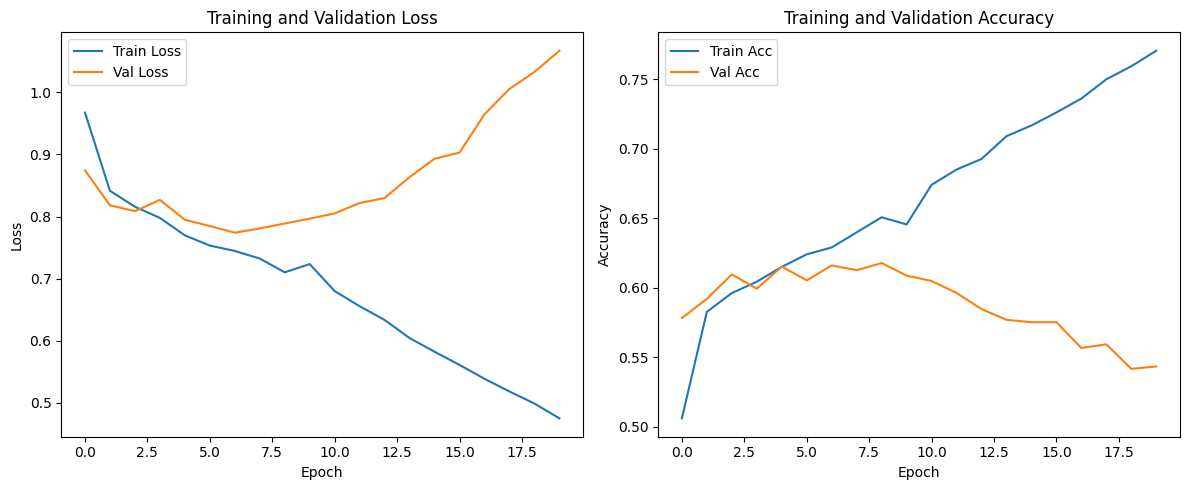

In [9]:
# Initialize Model
model = LSTMClassifier(
    vocab_size=22,  # 20 AAs + X + <pad>
    embed_dim=256,
    hidden_dim=64,
    num_layers=2,
    num_classes=len(datamodule.label2idx),
    bidir=True
)

# Train
history = train_model(model, datamodule)

# Plot
plot_training_history(history)

<h3>Test the Model</h3>

In [10]:
# preprocess testset
test_csv_path = os.path.join(notebook_dir, "../data/test.csv")
print("Test CSV path:", test_csv_path)

def create_test_dataloader(datamodule, test_csv_path, batch_size=None):
    # load and preprocess test data
    test_df = pd.read_csv(test_csv_path)
    test_df = test_df.dropna(subset=["sequence", "location"]).drop_duplicates()

    # create test dataset using original mappings
    test_ds = ProteinSequenceDataset(
        test_df,
        aa2idx=datamodule.vocab,
        label2idx=datamodule.label_mappings
    )

    # get test dataloader
    return DataLoader(
        test_ds,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=datamodule.collate_fn,
        num_workers=4
    )

# create dataloader
test_loader = create_test_dataloader(
    datamodule=datamodule,
    test_csv_path=test_csv_path,
    batch_size=64 # batch size from tuning
)

Test CSV path: /content/drive/MyDrive/Chuks/notebooks/../data/test.csv


In [11]:
# test the model on unseen data
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = test_model(model, test_loader, criterion)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")

Test Loss: 0.6147, Test Accuracy: 0.7272
